# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, the goal is to compare the performance of the classifiers encountered in this section of the program, namely **K-Nearest Neighbors, Logistic Regression, Decision Trees, and Support Vector Machines**, on a dataset describing a Portuguese bank's telephone marketing campaigns for a term-deposit product.

The notebook follows the CRISP-DM process: Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation, closing with findings and recommendations written for a non-technical audience.

**Contents**
1. Understanding the data (Problems 1–3)
2. Business objective and exploratory analysis (Problem 4)
3. Feature engineering, train/test split and baseline (Problems 5–7)
4. A simple model and default-settings comparison (Problems 8–10)
5. Improving the models: feature set, metric choice, grid search (Problem 11)
6. Findings, actionable insights and next steps

### Getting Started

The dataset comes from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/bank+marketing). It is a collection of the results of multiple marketing campaigns run by a Portuguese bank. The accompanying paper, Moro, Laureano & Cortez, *Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology* (2011), provides more information on the data and features.

In [1]:
# Core libraries
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# scikit-learn: preprocessing, model selection, models and metrics
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.float_format', '{:.3f}'.format)

RANDOM_STATE = 42  # fixed seed so results are reproducible

### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper. How many marketing campaigns does this data represent?

**Answer:** According to the *Materials and Methods* section of the paper, the data relates to **17 telephone marketing campaigns** run by the bank's own contact centre **between May 2008 and November 2010**, covering 79,354 contacts in the original database. The product offered was a long-term deposit with an attractive interest rate.

The public file used here (`bank-additional-full.csv`) is a cleaned subset of that data: 41,188 contacts, 20 input attributes (including five national social/economic indicators from Banco de Portugal) and the target.

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [2]:
# The file is semicolon-separated
bank_df = pd.read_csv('data/bank-additional-full.csv', sep=';')
print(f'Rows: {bank_df.shape[0]:,}  |  Columns: {bank_df.shape[1]}')

Rows: 41,188  |  Columns: 21


In [3]:
bank_df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,5191.000,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,5191.000,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,5191.000,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,5191.000,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,5191.000,no


### Problem 3: Understanding the Features

Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.

```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical)
3 - marital : marital status (categorical; 'divorced' means divorced or widowed)
4 - education (categorical)
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical)
10 - day_of_week: last contact day of the week (categorical)
11 - duration: last contact duration, in seconds (numeric). Only known after the call, so it
     should be discarded for a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign for this client
13 - pdays: days since the client was last contacted in a previous campaign (999 = never)
14 - previous: number of contacts performed before this campaign for this client
15 - poutcome: outcome of the previous marketing campaign
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator
17 - cons.price.idx: consumer price index - monthly indicator
18 - cons.conf.idx: consumer confidence index - monthly indicator
19 - euribor3m: euribor 3 month rate - daily indicator
20 - nr.employed: number of employees - quarterly indicator

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```

In [4]:
bank_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [5]:
# No NaNs are present, but missing values are encoded with the string 'unknown'
print('Explicit NaN values:', bank_df.isna().sum().sum())

unknown_counts = (bank_df == 'unknown').sum()
unknown_summary = pd.DataFrame({
    'unknown_count': unknown_counts,
    'unknown_pct': unknown_counts / len(bank_df) * 100
}).query('unknown_count > 0').sort_values('unknown_pct', ascending=False)
unknown_summary

Explicit NaN values: 0


,unknown_count,unknown_pct
default,8597,20.873
education,1731,4.203
housing,990,2.404
loan,990,2.404
job,330,0.801
marital,80,0.194


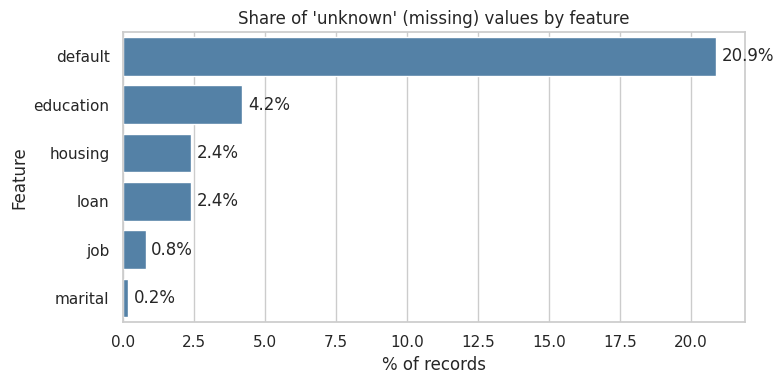

In [6]:
# Visualise the share of 'unknown' values per categorical column
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=unknown_summary['unknown_pct'], y=unknown_summary.index, ax=ax, color='steelblue')
ax.set_title("Share of 'unknown' (missing) values by feature")
ax.set_xlabel('% of records')
ax.set_ylabel('Feature')
for i, v in enumerate(unknown_summary['unknown_pct']):
    ax.text(v + 0.2, i, f'{v:.1f}%', va='center')
plt.tight_layout()
plt.savefig('images/unknown_values.png', dpi=120)
plt.show()

In [7]:
# Other data-quality checks
print('Duplicate rows:', bank_df.duplicated().sum())
print(f"pdays == 999 (never contacted before): {(bank_df['pdays'] == 999).mean():.1%}")
print('default value counts:', bank_df['default'].value_counts().to_dict())

Duplicate rows: 12
pdays == 999 (never contacted before): 96.3%
default value counts: {'no': 32588, 'unknown': 8597, 'yes': 3}


In [8]:
# Clean-up based on the checks above
bank_df = bank_df.drop_duplicates().reset_index(drop=True)

# Target: coerce 'yes'/'no' strings into a 1/0 integer
bank_df['y'] = (bank_df['y'] == 'yes').astype(int)

# pdays uses 999 as a sentinel; replace it with an explicit binary flag
bank_df['prev_contacted'] = (bank_df['pdays'] != 999).astype(int)

print(f'Rows after removing duplicates: {len(bank_df):,}')

Rows after removing duplicates: 41,176


**Observations**

- **No `NaN` values**, but six categorical columns use the label `'unknown'` for missing data. The largest is `default` (~21%). Because "unknown" may itself carry information (a client who doesn't disclose their credit status may behave differently), and dropping rows would lose a fifth of the data, `'unknown'` is **kept as its own category** and one-hot encoded.
- `default = 'yes'` occurs only 3 times, so the feature is essentially "no" vs "unknown".
- **12 duplicate rows** were removed.
- **Data types:** numeric columns are already numeric and categorical columns are strings, so no coercion is needed except for the **target `y`**, converted from `'yes'/'no'` to `1/0`.
- **`pdays`** uses `999` as a "never contacted" sentinel (~96% of rows). Treating 999 as a real number of days would distort distance-based models, so it is replaced by a binary `prev_contacted` flag.
- **`duration`** is only known after the call ends (and `duration = 0` guarantees `y = 'no'`), so it is a **data leak** and is excluded from all models.

### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task. State the objective below.

**Business Objective**

The bank runs outbound telephone campaigns to sell a long-term deposit. Every call costs agent time and money, and only about 1 in 9 calls converts. Unwanted calls can also irritate clients.

> **Goal:** build a model that, *before a call is made*, predicts the likelihood that a client will subscribe to the term deposit, so the bank can **rank and prioritise who to call**: reaching most of the would-be subscribers with far fewer calls.

This is a **binary classification** problem (`y = 1` subscribed, `y = 0` did not). Because the model must be usable before dialling, only information available ahead of the call is used (`duration` is excluded). Success is measured not by raw accuracy, but by how well the model **ranks likely subscribers at the top of the call list** (see Problem 11 for the metric rationale).

#### Exploratory Data Analysis

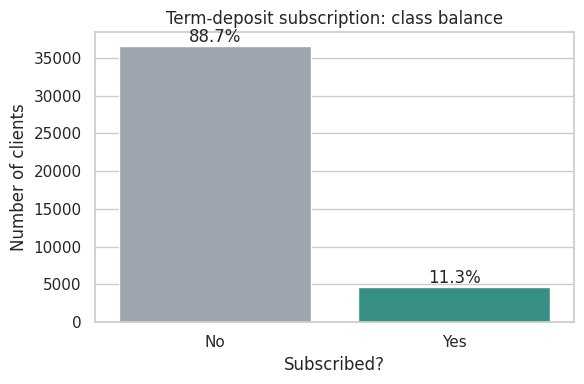

In [9]:
# Class balance of the target
target_share = bank_df['y'].value_counts(normalize=True).rename({0: 'No', 1: 'Yes'})

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=bank_df['y'].map({0: 'No', 1: 'Yes'}), order=['No', 'Yes'], ax=ax,
              hue=bank_df['y'].map({0: 'No', 1: 'Yes'}), palette=['#9aa5b1', '#2a9d8f'], legend=False)
ax.set_title('Term-deposit subscription: class balance')
ax.set_xlabel('Subscribed?')
ax.set_ylabel('Number of clients')
for p, share in zip(ax.patches, target_share[['No', 'Yes']].values):
    ax.annotate(f'{share:.1%}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.savefig('images/class_balance.png', dpi=120)
plt.show()

The target is **imbalanced**: only ~11.3% of contacts result in a subscription. A model that always predicts "No" would be ~88.7% accurate while being useless for the business, an early warning that accuracy is the wrong yardstick.

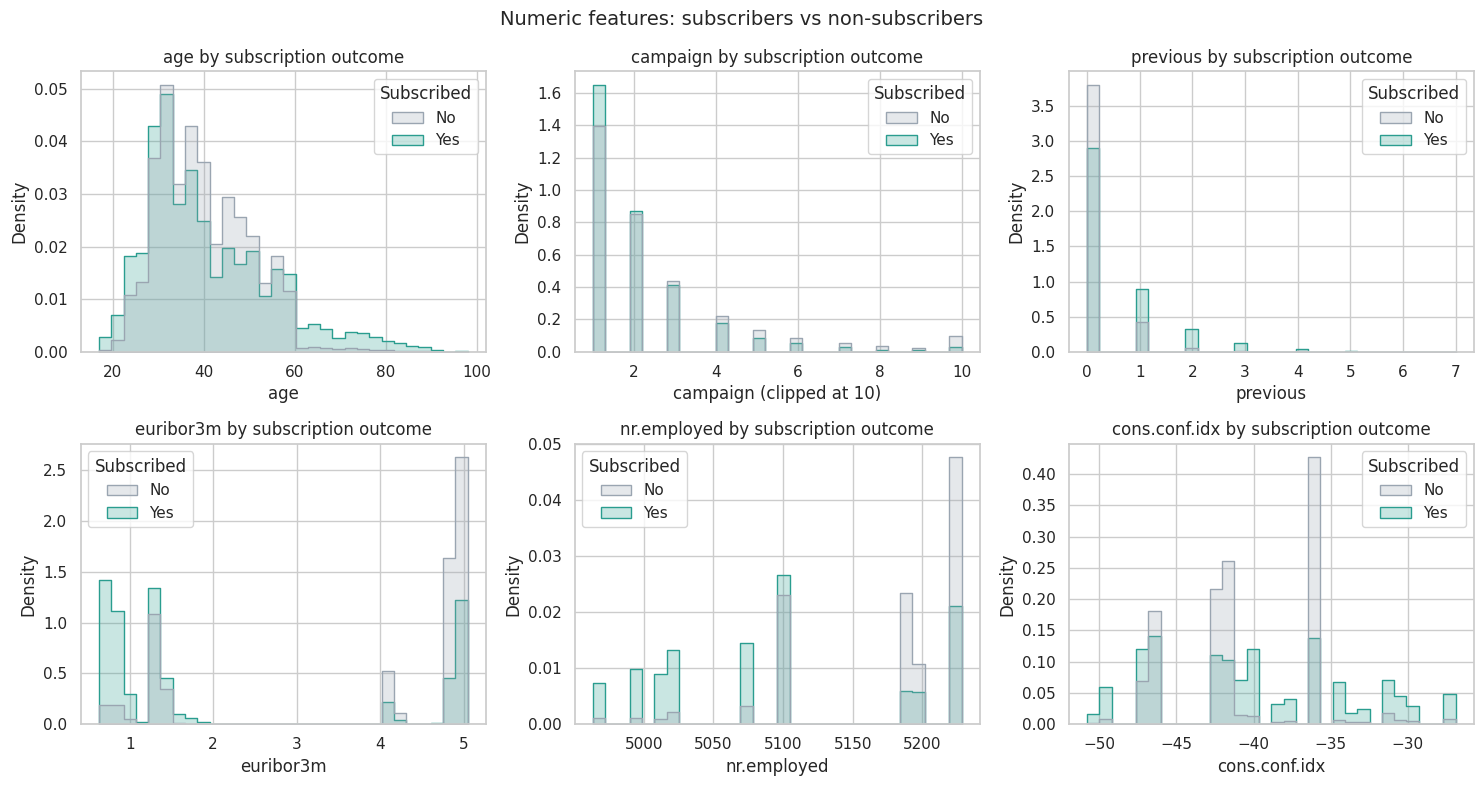

In [10]:
# Distributions of key numeric features split by outcome (densities, so classes are comparable)
numeric_to_plot = ['age', 'campaign', 'previous', 'euribor3m', 'nr.employed', 'cons.conf.idx']
plot_df = bank_df.assign(Subscribed=bank_df['y'].map({0: 'No', 1: 'Yes'}),
                         campaign=bank_df['campaign'].clip(upper=10))  # clip long tail for readability

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_to_plot):
    sns.histplot(data=plot_df, x=col, hue='Subscribed', hue_order=['No', 'Yes'], stat='density',
                 common_norm=False, bins=30, element='step', ax=ax, palette=['#9aa5b1', '#2a9d8f'])
    ax.set_title(f'{col} by subscription outcome')
    ax.set_ylabel('Density')
axes[0, 1].set_xlabel('campaign (clipped at 10)')
plt.suptitle('Numeric features: subscribers vs non-subscribers', fontsize=14)
plt.tight_layout()
plt.savefig('images/numeric_distributions.png', dpi=120)
plt.show()

- **Age:** subscribers are over-represented at both ends: young adults (often students) and clients over 60.
- **campaign:** conversion falls as the number of calls in the current campaign rises; repeated calling has diminishing returns.
- **previous:** clients contacted in earlier campaigns are more likely to subscribe.
- **Macro indicators** (`euribor3m`, `nr.employed`): subscriptions concentrate in periods of **low interest rates and lower employment**, a strong economic-context signal.

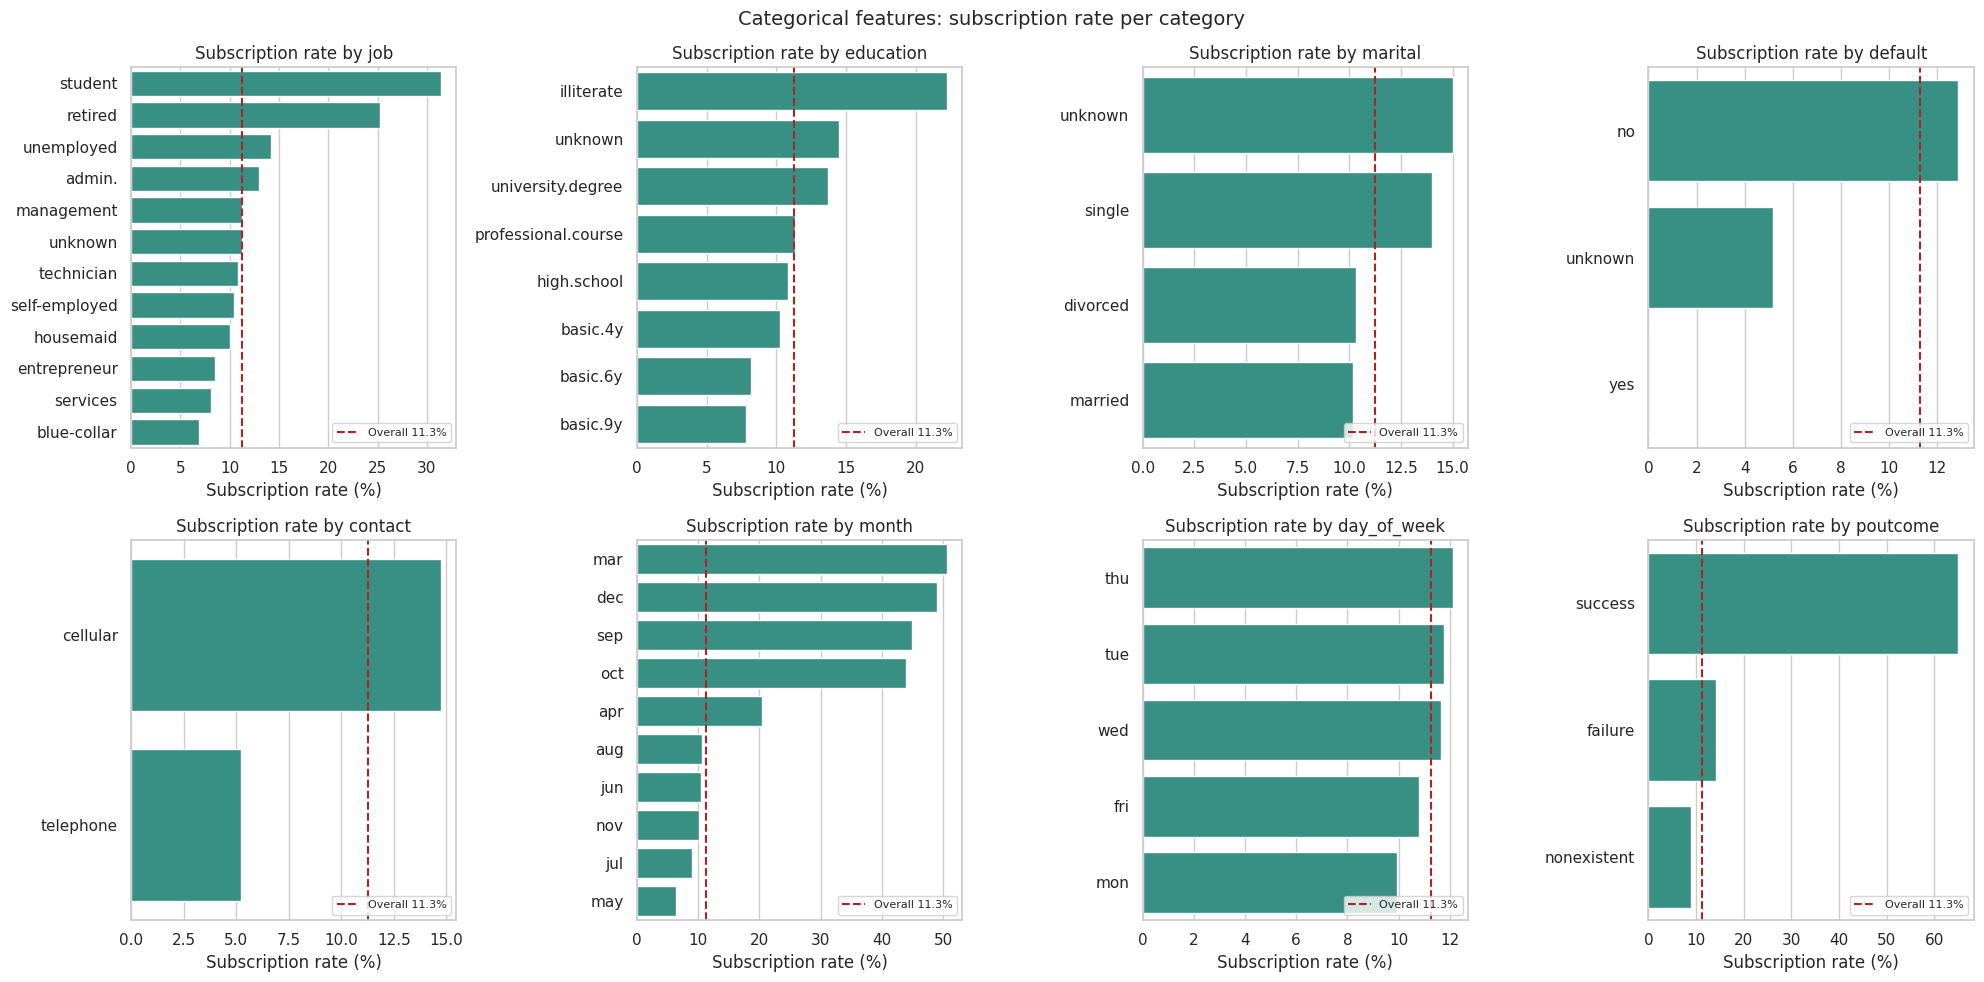

In [11]:
# Subscription rate by category for the main categorical features
cat_to_plot = ['job', 'education', 'marital', 'default', 'contact', 'month', 'day_of_week', 'poutcome']
overall_rate = bank_df['y'].mean()

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, col in zip(axes.flat, cat_to_plot):
    rates = bank_df.groupby(col)['y'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rates.values, y=rates.index, ax=ax, color='#2a9d8f')
    ax.axvline(overall_rate * 100, color='firebrick', linestyle='--', label=f'Overall {overall_rate:.1%}')
    ax.set_title(f'Subscription rate by {col}')
    ax.set_xlabel('Subscription rate (%)')
    ax.set_ylabel('')
    ax.legend(loc='lower right', fontsize=8)
plt.suptitle('Categorical features: subscription rate per category', fontsize=14)
plt.tight_layout()
plt.savefig('images/categorical_rates.png', dpi=120)
plt.show()

- **poutcome = success**: clients who said yes in a previous campaign convert at ~65%, roughly 6x the average.
- **Month:** March, September, October and December convert far above average (but are low-volume months); May is the busiest month and the worst performer.
- **Contact channel:** cellular contacts convert at roughly 3x the rate of landline contacts.
- **Job:** students and retirees are the most responsive; blue-collar and services the least.
- `day_of_week` and `marital` show little variation, so they are likely weak predictors.

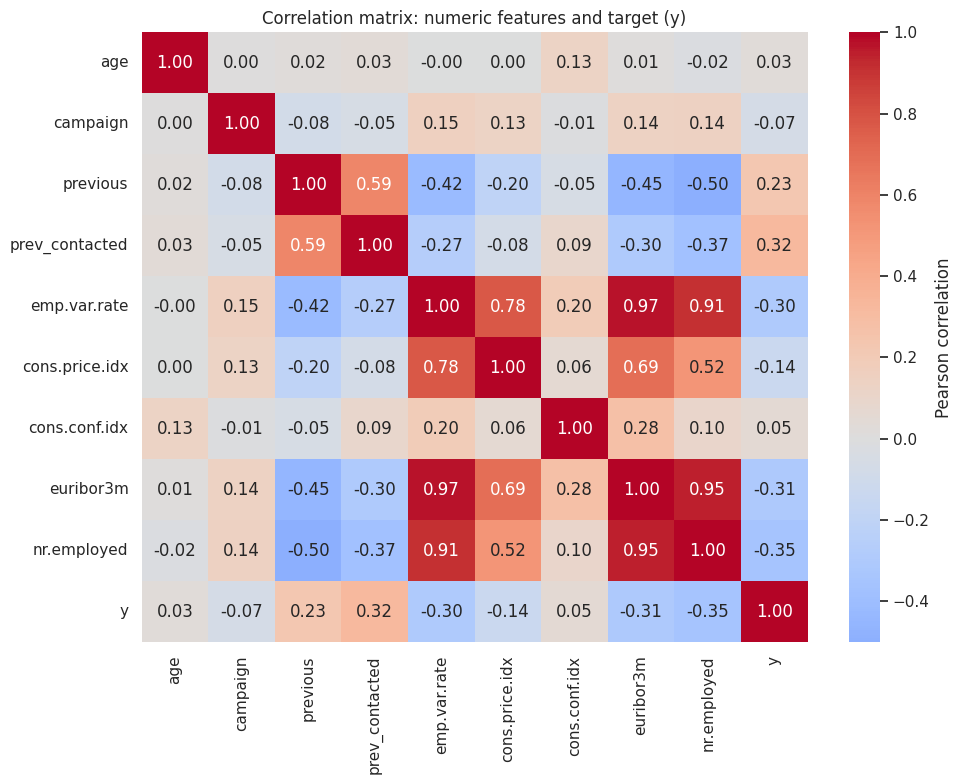

In [12]:
# Correlation between numeric features and the target
numeric_cols = ['age', 'campaign', 'previous', 'prev_contacted', 'emp.var.rate',
                'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(bank_df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, cbar_kws={'label': 'Pearson correlation'})
ax.set_title('Correlation matrix: numeric features and target (y)')
plt.tight_layout()
plt.savefig('images/correlation_heatmap.png', dpi=120)
plt.show()

`emp.var.rate`, `euribor3m` and `nr.employed` are almost perfectly correlated with each other (r > 0.9): they all describe the same economic cycle. This multicollinearity does not hurt predictions, but it means the individual logistic-regression coefficients of these three features should not be over-interpreted. `nr.employed` has the strongest (negative) linear relationship with subscription.

#### Inferential statistics: is each feature associated with subscription?

- **Categorical features:** chi-square test of independence (H0: the subscription rate is the same across categories). Cramér's V measures the *strength* of the association (0 = none, 1 = perfect).
- **Numeric features:** Mann–Whitney U test (H0: subscribers and non-subscribers have the same distribution). It is non-parametric, which suits the skewed numeric features. The rank-biserial correlation gives the effect size (positive = higher values among subscribers).

In [13]:
def cramers_v(table):
    """Cramér's V effect size from a contingency table."""
    chi2 = stats.chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

cat_features = ['job', 'marital', 'education', 'default', 'housing', 'loan',
                'contact', 'month', 'day_of_week', 'poutcome']
chi_rows = []
for col in cat_features:
    table = pd.crosstab(bank_df[col], bank_df['y'])
    chi2, p_value, dof, _ = stats.chi2_contingency(table)
    chi_rows.append({'feature': col, 'chi2': chi2, 'p_value': p_value, 'cramers_v': cramers_v(table)})
chi_results = pd.DataFrame(chi_rows).sort_values('cramers_v', ascending=False).set_index('feature')
chi_results['significant (p<0.05)'] = chi_results['p_value'] < 0.05
chi_results

,chi2,p_value,cramers_v,significant (p<0.05)
feature,,,,
poutcome,4230.143,0.000,0.321,True
month,3103.033,0.000,0.275,True
job,961.744,0.000,0.153,True
contact,862.081,0.000,0.145,True
default,406.556,0.000,0.099,True
education,192.849,0.000,0.068,True
marital,122.959,0.000,0.055,True
day_of_week,26.054,0.000,0.025,True
housing,5.742,0.057,0.012,False


In [14]:
num_features = ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx',
                'cons.conf.idx', 'euribor3m', 'nr.employed']
subscribers, non_subscribers = bank_df[bank_df['y'] == 1], bank_df[bank_df['y'] == 0]
mw_rows = []
for col in num_features:
    u_stat, p_value = stats.mannwhitneyu(subscribers[col], non_subscribers[col])
    rank_biserial = 2 * u_stat / (len(subscribers) * len(non_subscribers)) - 1
    mw_rows.append({'feature': col, 'median_yes': subscribers[col].median(),
                    'median_no': non_subscribers[col].median(), 'p_value': p_value,
                    'effect_size': rank_biserial})
mw_results = (pd.DataFrame(mw_rows).set_index('feature')
              .sort_values('effect_size', key=abs, ascending=False))
mw_results

,median_yes,median_no,p_value,effect_size
feature,,,,
nr.employed,5099.100,5195.800,0.000,-0.498
euribor3m,1.266,4.857,0.000,-0.487
emp.var.rate,-1.800,1.100,0.000,-0.433
cons.price.idx,93.200,93.918,0.000,-0.221
previous,0.000,0.000,0.000,0.219
campaign,2.000,2.000,0.000,-0.110
cons.conf.idx,-40.400,-41.800,0.000,0.074
age,37.000,38.000,0.016,-0.022


**Interpretation**

- With ~41,000 rows, almost everything is "statistically significant", so **effect size matters more than the p-value**. Only `housing` (p = 0.057) and `loan` (p = 0.58) fail the chi-square test: having a housing or personal loan is **not associated** with subscribing.
- The strongest categorical associations are **`poutcome`** (Cramér's V = 0.32) and **`month`** (0.28), followed by `job` and `contact` (~0.15). `day_of_week` and `marital` are significant but negligible (V < 0.06).
- Among numeric features, the **macro-economic indicators dominate**: subscribers were contacted when `euribor3m` had a median of 1.27% versus 4.86% for non-subscribers, and `nr.employed` was lower (rank-biserial effect ≈ −0.5, a large effect).
- **Age** is significant (p = 0.016) but with a near-zero effect size, because its relationship is U-shaped (both the young and the over-60s convert more), so the medians barely differ. `campaign` has a small negative effect: more calls, fewer subscriptions.
- Personal client attributes have weak-to-modest effects, which foreshadows Problems 8–10: a model built only on them will struggle.

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started. Before we can do this, we must work to encode the data. Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [15]:
# Bank client information features only (attributes 1-7)
bank_num_features = ['age']
bank_cat_features = ['job', 'marital', 'education', 'default', 'housing', 'loan']

X_bank = bank_df[bank_num_features + bank_cat_features]
y = bank_df['y']

# Scale the numeric column (needed by KNN, SVM and regularised logistic regression)
# and one-hot encode the categoricals ('unknown' becomes its own column).
bank_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), bank_num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), bank_cat_features)
])

print('Feature matrix shape before encoding:', X_bank.shape)
print('Feature matrix shape after encoding: ', bank_preprocessor.fit_transform(X_bank).shape)

Feature matrix shape before encoding: (41176, 7)
Feature matrix shape after encoding:  (41176, 34)


The preprocessing lives inside a `ColumnTransformer` that is placed in a `Pipeline` with each model. This way the scaler and encoder are **fitted only on training data** (in every cross-validation fold too), which prevents information from the test set leaking into the model.

### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [16]:
# 70/30 split, stratified so both sets keep the ~11% subscription rate
X_train_bank, X_test_bank, y_train, y_test = train_test_split(
    X_bank, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

print(f'Train: {X_train_bank.shape[0]:,} rows  |  Test: {X_test_bank.shape[0]:,} rows')
print(f'Subscription rate - train: {y_train.mean():.2%}  test: {y_test.mean():.2%}')

Train: 28,823 rows  |  Test: 12,353 rows
Subscription rate - train: 11.27%  test: 11.27%


### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline. What is the baseline performance that our classifier should aim to beat?

In [17]:
# Baseline: always predict the majority class ("No")
baseline = DummyClassifier(strategy='most_frequent').fit(X_train_bank, y_train)
baseline_preds = baseline.predict(X_test_bank)

print(f'Baseline test accuracy: {accuracy_score(y_test, baseline_preds):.4f}')
print(f'Baseline recall (share of subscribers found): {recall_score(y_test, baseline_preds):.2f}')
print('Baseline ROC-AUC: 0.50 (a constant prediction cannot rank clients)')

Baseline test accuracy: 0.8873
Baseline recall (share of subscribers found): 0.00
Baseline ROC-AUC: 0.50 (a constant prediction cannot rank clients)


The baseline to beat is **~88.7% accuracy**, the share of clients who did *not* subscribe. This baseline finds **zero** subscribers, so any useful model must beat it on accuracy *and* actually identify subscribers. For ranking quality the baseline is a ROC-AUC of **0.50** (random ordering).

### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.

In [18]:
logreg_simple = Pipeline([
    ('preprocess', bank_preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])
logreg_simple.fit(X_train_bank, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers cont

### Problem 9: Score the Model

What is the accuracy of your model?

In [19]:
simple_test_preds = logreg_simple.predict(X_test_bank)
simple_test_probs = logreg_simple.predict_proba(X_test_bank)[:, 1]

print(f'Train accuracy: {logreg_simple.score(X_train_bank, y_train):.4f}')
print(f'Test accuracy:  {accuracy_score(y_test, simple_test_preds):.4f}')
print(f'Test ROC-AUC:   {roc_auc_score(y_test, simple_test_probs):.4f}')
print(f'Clients predicted to subscribe: {simple_test_preds.sum()} of {len(simple_test_preds):,}')

Train accuracy: 0.8873
Test accuracy:  0.8873
Test ROC-AUC:   0.6501
Clients predicted to subscribe: 0 of 12,353


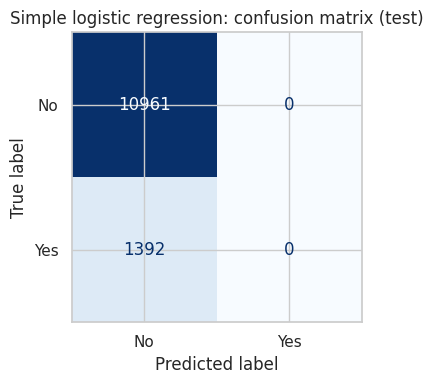

In [20]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, simple_test_preds, display_labels=['No', 'Yes'],
                                        cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Simple logistic regression: confusion matrix (test)')
plt.tight_layout()
plt.show()

**The model's accuracy is 88.73% on the test set: exactly the baseline.** With only personal client attributes and the default 0.5 probability threshold, logistic regression predicts "No" for **every single client** (0 of 12,353 flagged), so it finds no subscribers at all.

Its ROC-AUC of 0.65 shows the bank features carry *some* ranking signal (better than the 0.50 of random ordering), but never enough to push any client's predicted probability above 50%. Accuracy hides this completely.

### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models. Using the default settings for each of the models, fit and score each. Also, be sure to compare the fit time of each of the models. Present your findings in a `DataFrame`.

In [21]:
def ranking_scores(fitted_model, X):
    """Continuous scores for ROC-AUC: probabilities if available, else SVM decision values."""
    if hasattr(fitted_model, 'predict_proba'):
        try:
            return fitted_model.predict_proba(X)[:, 1]
        except AttributeError:
            pass
    return fitted_model.decision_function(X)

default_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'SVM': SVC(random_state=RANDOM_STATE),
}

default_rows = []
for name, estimator in default_models.items():
    pipe = Pipeline([('preprocess', bank_preprocessor), ('model', estimator)])
    start = time.time()
    pipe.fit(X_train_bank, y_train)
    fit_seconds = time.time() - start
    test_preds = pipe.predict(X_test_bank)
    default_rows.append({
        'Model': name,
        'Train Time (s)': fit_seconds,
        'Train Accuracy': pipe.score(X_train_bank, y_train),
        'Test Accuracy': accuracy_score(y_test, test_preds),
        'Test Recall': recall_score(y_test, test_preds),
        'Test ROC-AUC': roc_auc_score(y_test, ranking_scores(pipe, X_test_bank)),
    })

default_results = pd.DataFrame(default_rows).set_index('Model')
default_results

,Train Time (s),Train Accuracy,Test Accuracy,Test Recall,Test ROC-AUC
Model,,,,,
Logistic Regression,0.135,0.887,0.887,0.000,0.650
KNN,0.071,0.892,0.879,0.072,0.593
Decision Tree,1.080,0.919,0.863,0.092,0.580
SVM,93.221,0.888,0.887,0.009,0.591


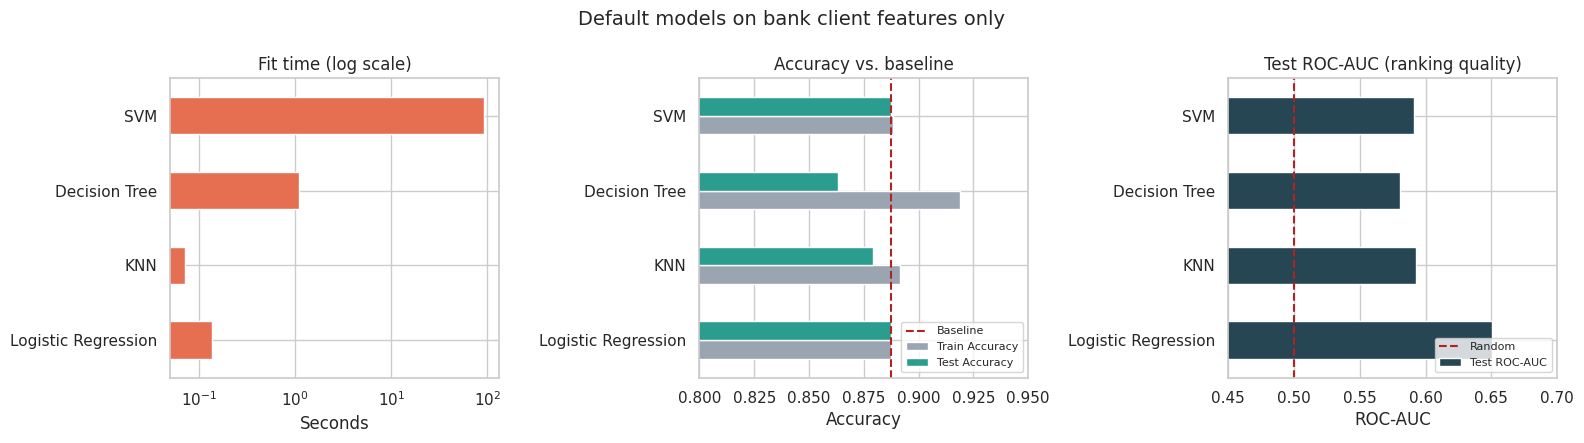

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

default_results['Train Time (s)'].plot.barh(ax=axes[0], color='#e76f51')
axes[0].set_xscale('log')
axes[0].set_title('Fit time (log scale)')
axes[0].set_xlabel('Seconds')

default_results[['Train Accuracy', 'Test Accuracy']].plot.barh(ax=axes[1], color=['#9aa5b1', '#2a9d8f'])
axes[1].axvline(target_share['No'], color='firebrick', linestyle='--', label='Baseline')
axes[1].set_xlim(0.8, 0.95)
axes[1].set_title('Accuracy vs. baseline')
axes[1].set_xlabel('Accuracy')
axes[1].legend(loc='lower right', fontsize=8)

default_results['Test ROC-AUC'].plot.barh(ax=axes[2], color='#264653')
axes[2].axvline(0.5, color='firebrick', linestyle='--', label='Random')
axes[2].set_xlim(0.45, 0.7)
axes[2].set_title('Test ROC-AUC (ranking quality)')
axes[2].set_xlabel('ROC-AUC')
axes[2].legend(loc='lower right', fontsize=8)

for ax in axes:
    ax.set_ylabel('')
plt.suptitle('Default models on bank client features only', fontsize=14)
plt.tight_layout()
plt.savefig('images/default_model_comparison.png', dpi=120)
plt.show()

**Observations (default settings, bank-client features only)**

- **No model beats the 88.7% baseline on test accuracy.** Logistic Regression and SVM essentially predict "No" for everyone (recall 0% and 1%). KNN and the Decision Tree flag a few clients but find under 10% of subscribers and score *below* baseline accuracy.
- **The Decision Tree overfits**: 91.9% train vs 86.3% test accuracy, because an unpruned tree memorises the training data. KNN shows the same pattern to a smaller degree.
- **Fit time varies by roughly 1,000x.** KNN (0.07s) and Logistic Regression (0.14s) are near-instant and the Decision Tree takes about a second, while **SVM needs ~90 seconds**. KNN's low "fit" time is misleading, since all its work happens at prediction time. SVM's cost grows rapidly with data size, which matters for frequent retraining.
- Ranking quality is weak across the board (ROC-AUC 0.58–0.65), and the simplest model, Logistic Regression, ranks best. **The limitation is the feature set, not the algorithm**: personal attributes alone don't explain who subscribes. This motivates Problem 11.

### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these. Below, we list a few things to explore in this pursuit.

- More feature engineering and exploration.
- Hyperparameter tuning and grid search.
- Adjust your performance metric.

#### 11.1 Choosing the evaluation metric

**Primary metric: ROC-AUC**, supported by **recall, precision and lift** at the operating point.

Rationale:
1. **Class imbalance makes accuracy misleading.** As shown above, a do-nothing model scores 88.7%.
2. **The business decision is a ranking problem.** The call centre has a fixed capacity and needs to know *who to call first*. ROC-AUC measures exactly this: the probability that a randomly chosen subscriber is ranked above a randomly chosen non-subscriber, independent of any single cut-off.
3. **Asymmetric costs.** Missing a subscriber (a lost deposit) costs much more than one extra phone call, so **recall** on the "Yes" class matters more than precision. Both are reported so the trade-off is visible.
4. **Comparability.** The original paper evaluates models with AUC and lift, so our results can be benchmarked against it.

Grid searches below therefore optimise `scoring='roc_auc'`.

#### 11.2 Feature engineering: use all information available *before* the call

The bank-only features were too weak. We add the campaign context (channel, month, day, number of contacts, previous-campaign history) and the five macro-economic indicators. `duration` stays excluded (leakage) and `pdays` is represented by the `prev_contacted` flag created earlier.

In [23]:
full_num_features = ['age', 'campaign', 'previous', 'prev_contacted', 'emp.var.rate',
                     'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
full_cat_features = ['job', 'marital', 'education', 'default', 'housing', 'loan',
                     'contact', 'month', 'day_of_week', 'poutcome']

X_full = bank_df[full_num_features + full_cat_features]

full_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), full_num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), full_cat_features)
])

# Same random_state and stratification -> same rows in train/test as before
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

print('Encoded feature count:', full_preprocessor.fit(X_train).transform(X_train).shape[1])

Encoded feature count: 62


#### 11.3 Hyperparameter tuning with cross-validated grid search

Each model is tuned with `GridSearchCV` using **stratified 5-fold cross-validation** on the training set only. The test set is touched once, at the end.

| Model | Hyperparameters searched | Why |
|---|---|---|
| Logistic Regression | `C` (regularisation strength), `class_weight` | Controls over/under-fitting; `balanced` up-weights the rare "Yes" class |
| KNN | `n_neighbors`, `weights` | Larger k gives smoother probability estimates for ranking |
| Decision Tree | `max_depth`, `min_samples_leaf`, `class_weight` | Pruning to stop the overfitting seen in Problem 10 |
| SVM | `C`, `gamma` | Margin softness and RBF kernel width |

Because SVM training time grows roughly quadratically with the number of rows (see the fit times in Problem 10), its grid search uses a **stratified 10,000-row subsample** with 3-fold CV; the best configuration is then refitted on the full training set.

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_spaces = {
    'Logistic Regression': (LogisticRegression(max_iter=2000),
                            {'model__C': [0.01, 0.1, 1, 10],
                             'model__class_weight': [None, 'balanced']}),
    'KNN': (KNeighborsClassifier(),
            {'model__n_neighbors': [15, 51, 101],
             'model__weights': ['uniform', 'distance']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {'model__max_depth': [3, 5, 7, 10],
                       'model__min_samples_leaf': [20, 50, 100],
                       'model__class_weight': [None, 'balanced']}),
}

tuned_models, tuned_info = {}, {}
for name, (estimator, grid) in search_spaces.items():
    pipe = Pipeline([('preprocess', full_preprocessor), ('model', estimator)])
    search = GridSearchCV(pipe, grid, scoring='roc_auc', cv=cv, n_jobs=-1)
    start = time.time()
    search.fit(X_train, y_train)
    tuned_info[name] = {'search_time': time.time() - start,
                        'best_params': search.best_params_,
                        'cv_roc_auc': search.best_score_}
    tuned_models[name] = search.best_estimator_
    print(f"{name:<20} CV ROC-AUC = {search.best_score_:.4f}  ({tuned_info[name]['search_time']:.0f}s)")

Logistic Regression  CV ROC-AUC = 0.7888  (18s)


KNN                  CV ROC-AUC = 0.7824  (58s)


Decision Tree        CV ROC-AUC = 0.7889  (37s)


In [25]:
# SVM: grid search on a stratified subsample, then refit the winner on the full training set
X_svm_sample, _, y_svm_sample, _ = train_test_split(
    X_train, y_train, train_size=10_000, stratify=y_train, random_state=RANDOM_STATE)

svm_pipe = Pipeline([('preprocess', full_preprocessor), ('model', SVC(random_state=RANDOM_STATE))])
svm_grid = {'model__C': [0.1, 1], 'model__gamma': ['scale', 0.01]}
svm_search = GridSearchCV(svm_pipe, svm_grid, scoring='roc_auc',
                          cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
                          n_jobs=-1)
start = time.time()
svm_search.fit(X_svm_sample, y_svm_sample)
search_time = time.time() - start

tuned_models['SVM'] = svm_pipe.set_params(**svm_search.best_params_)
tuned_info['SVM'] = {'search_time': search_time, 'best_params': svm_search.best_params_,
                     'cv_roc_auc': svm_search.best_score_}
print(f"{'SVM':<20} CV ROC-AUC = {svm_search.best_score_:.4f}  ({search_time:.0f}s, 10k subsample)")

SVM                  CV ROC-AUC = 0.7343  (50s, 10k subsample)


In [26]:
# Refit each tuned model on the full training set (timed), then evaluate on the untouched test set
tuned_rows, test_scores = [], {}
for name, model in tuned_models.items():
    start = time.time()
    model.fit(X_train, y_train)
    fit_seconds = time.time() - start

    test_preds = model.predict(X_test)
    test_scores[name] = ranking_scores(model, X_test)
    tuned_rows.append({
        'Model': name,
        'Best Params': ', '.join(f"{k.replace('model__', '')}={v}"
                                 for k, v in tuned_info[name]['best_params'].items()),
        'Train Time (s)': fit_seconds,
        'CV ROC-AUC': tuned_info[name]['cv_roc_auc'],
        'Train ROC-AUC': roc_auc_score(y_train, ranking_scores(model, X_train)),
        'Test ROC-AUC': roc_auc_score(y_test, test_scores[name]),
        'Test Accuracy': accuracy_score(y_test, test_preds),
        'Test Precision': precision_score(y_test, test_preds, zero_division=0),
        'Test Recall': recall_score(y_test, test_preds),
        'Test F1': f1_score(y_test, test_preds),
    })

tuned_results = pd.DataFrame(tuned_rows).set_index('Model').sort_values('Test ROC-AUC', ascending=False)
tuned_results

,Best Params,Train Time (s),CV ROC-AUC,Train ROC-AUC,Test ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1
Model,,,,,,,,,
Decision Tree,"class_weight=None, max_depth=7, min_samples_le...",0.313,0.789,0.800,0.806,0.898,0.640,0.221,0.329
Logistic Regression,"C=0.1, class_weight=balanced",0.491,0.789,0.793,0.803,0.830,0.358,0.648,0.461
KNN,"n_neighbors=101, weights=uniform",0.130,0.782,0.812,0.795,0.900,0.682,0.206,0.317
SVM,"C=1, gamma=scale",144.192,0.734,0.896,0.693,0.901,0.669,0.235,0.348


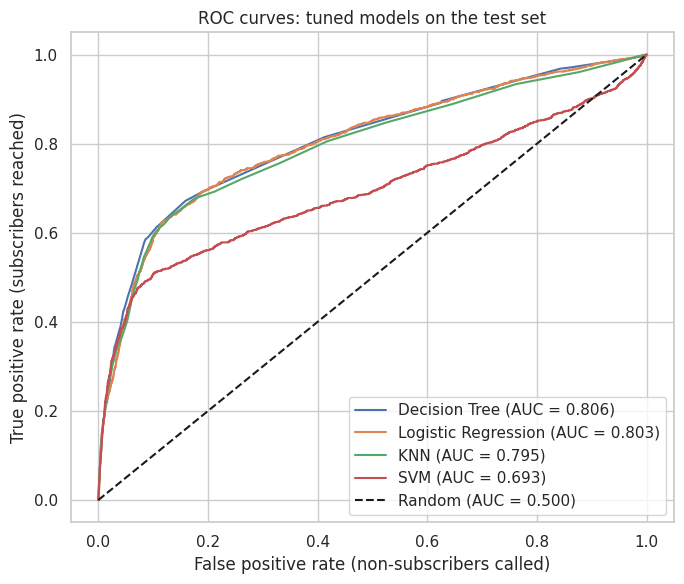

In [27]:
# ROC curves for the tuned models
fig, ax = plt.subplots(figsize=(7, 6))
for name in tuned_results.index:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC = {tuned_results.loc[name, 'Test ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.500)')
ax.set_title('ROC curves: tuned models on the test set')
ax.set_xlabel('False positive rate (non-subscribers called)')
ax.set_ylabel('True positive rate (subscribers reached)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('images/roc_curves.png', dpi=120)
plt.show()

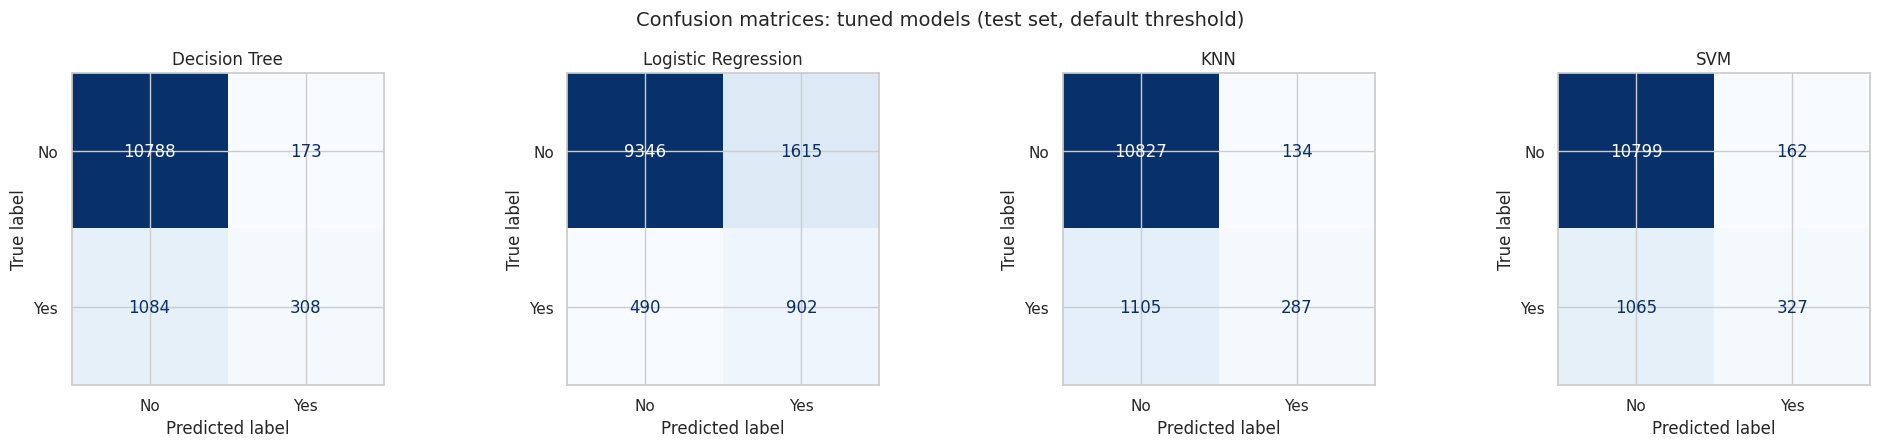

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, name in zip(axes, tuned_results.index):
    ConfusionMatrixDisplay.from_predictions(y_test, tuned_models[name].predict(X_test),
                                            display_labels=['No', 'Yes'], cmap='Blues',
                                            ax=ax, colorbar=False)
    ax.set_title(name)
plt.suptitle('Confusion matrices: tuned models (test set, default threshold)', fontsize=14)
plt.tight_layout()
plt.show()

**Reading the tuned results**

- **Every tuned model improves dramatically on Problem 10.** Test ROC-AUC rises from ~0.60 to **~0.80** for the Decision Tree (0.806), Logistic Regression (0.803) and KNN (0.795). The gain comes mostly from the richer pre-call features; tuning then removes the overfitting.
- **Cross-validation scores agree with the test scores** (CV ≈ 0.78–0.79, test ≈ 0.80) for these three models, so the results are not a lucky split.
- **The tuned SVM is the weak point**: train AUC 0.90 but test AUC 0.69, so it overfits. It is also ~300x slower to train (144s) than the others. Its grid was limited to a subsample and a small search because of that cost, so on this data size SVM is the worst cost/benefit choice.
- **Accuracy and recall tell different stories.** Grid search selected `class_weight='balanced'` for Logistic Regression, so at the default threshold it flags many more clients: **recall 65%** (it finds 2 of every 3 subscribers) at 36% precision, with accuracy dropping to 83%. The Tree, KNN and SVM keep ~90% accuracy but find only ~21–24% of subscribers. For a bank that would rather make an extra call than miss a depositor, the higher-recall model is more useful, which is exactly why accuracy was rejected as the selection metric.
- In practice the bank would not use a fixed 0.5 threshold at all. It would call clients **in order of predicted score** until capacity runs out, which is what the lift analysis below evaluates.

#### 11.4 Business evaluation: cumulative gains (lift)

If the call list is sorted by the model's score, what share of all subscribers is reached after calling the top X% of clients?

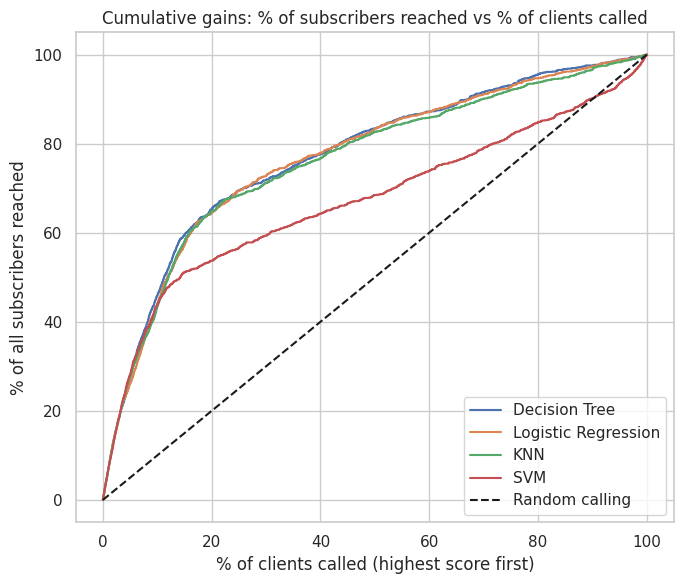

In [29]:
def cumulative_gains(y_true, scores):
    """Share of all positives captured when contacting clients in descending score order."""
    order = np.argsort(-np.asarray(scores))
    captured = np.cumsum(np.asarray(y_true)[order]) / np.sum(y_true)
    contacted = np.arange(1, len(order) + 1) / len(order)
    return contacted, captured

fig, ax = plt.subplots(figsize=(7, 6))
for name in tuned_results.index:
    contacted, captured = cumulative_gains(y_test, test_scores[name])
    ax.plot(contacted * 100, captured * 100, label=name)
ax.plot([0, 100], [0, 100], 'k--', label='Random calling')
ax.set_title('Cumulative gains: % of subscribers reached vs % of clients called')
ax.set_xlabel('% of clients called (highest score first)')
ax.set_ylabel('% of all subscribers reached')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('images/cumulative_gains.png', dpi=120)
plt.show()

In [30]:
# Targeting table for the best model
best_model_name = tuned_results.index[0]
contacted, captured = cumulative_gains(y_test, test_scores[best_model_name])
base_rate = y_test.mean()

targeting_rows = []
for pct in [0.10, 0.20, 0.30, 0.50]:
    idx = int(pct * len(contacted)) - 1
    conversion = captured[idx] * y_test.sum() / (idx + 1)
    targeting_rows.append({'Clients called': f'Top {pct:.0%}',
                           'Subscribers reached': f'{captured[idx]:.1%}',
                           'Conversion rate of calls': f'{conversion:.1%}',
                           'Lift vs random': f'{conversion / base_rate:.1f}x'})
print(f'Best model: {best_model_name} | random-call conversion rate: {base_rate:.1%}')
pd.DataFrame(targeting_rows).set_index('Clients called')

Best model: Decision Tree | random-call conversion rate: 11.3%


,Subscribers reached,Conversion rate of calls,Lift vs random
Clients called,,,
Top 10%,45.8%,51.7%,4.6x
Top 20%,65.2%,36.8%,3.3x
Top 30%,71.8%,27.0%,2.4x
Top 50%,83.5%,18.8%,1.7x


#### 11.5 Interpreting the models

**Logistic regression coefficients.** Numeric features are standardised and categorical features are 0/1 indicators, so a coefficient is the change in the **log-odds** of subscribing for a one-standard-deviation increase (numeric) or for belonging to that category (categorical). `exp(coef)` gives the **odds ratio**: e.g. 1.5 means the odds of subscribing are 50% higher, 0.7 means 30% lower, holding the other features constant.

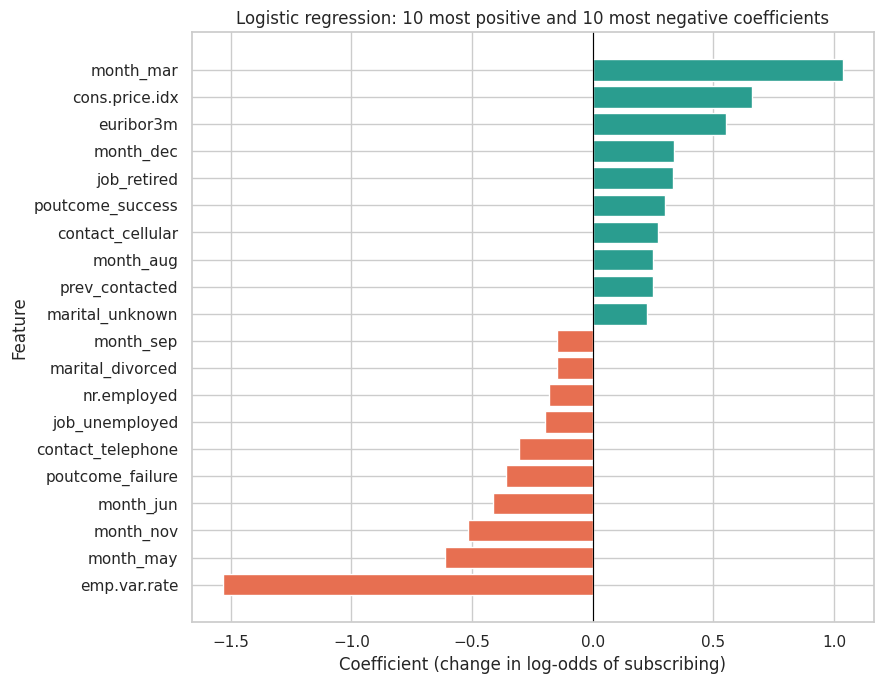

In [31]:
logreg_tuned = tuned_models['Logistic Regression']
feature_names = (pd.Index(logreg_tuned.named_steps['preprocess'].get_feature_names_out())
                 .str.replace('num__', '').str.replace('cat__', ''))
coefficients = pd.DataFrame({'feature': feature_names,
                             'coefficient': logreg_tuned.named_steps['model'].coef_[0]})
coefficients['odds_ratio'] = np.exp(coefficients['coefficient'])

top_coefs = pd.concat([coefficients.nlargest(10, 'coefficient'),
                       coefficients.nsmallest(10, 'coefficient')]).sort_values('coefficient')

fig, ax = plt.subplots(figsize=(9, 7))
colors = ['#e76f51' if c < 0 else '#2a9d8f' for c in top_coefs['coefficient']]
ax.barh(top_coefs['feature'], top_coefs['coefficient'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Logistic regression: 10 most positive and 10 most negative coefficients')
ax.set_xlabel('Coefficient (change in log-odds of subscribing)')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.savefig('images/logreg_coefficients.png', dpi=120)
plt.show()

In [32]:
# Odds ratios for the business-relevant (non-macro) features
macro_features = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
(coefficients[~coefficients['feature'].isin(macro_features)]
 .sort_values('coefficient', key=abs, ascending=False)
 .head(10)
 .set_index('feature'))

,coefficient,odds_ratio
feature,,
month_mar,1.038,2.822
month_may,-0.613,0.542
month_nov,-0.517,0.596
month_jun,-0.415,0.661
poutcome_failure,-0.358,0.699
month_dec,0.336,1.400
job_retired,0.333,1.394
contact_telephone,-0.304,0.738
poutcome_success,0.299,1.349


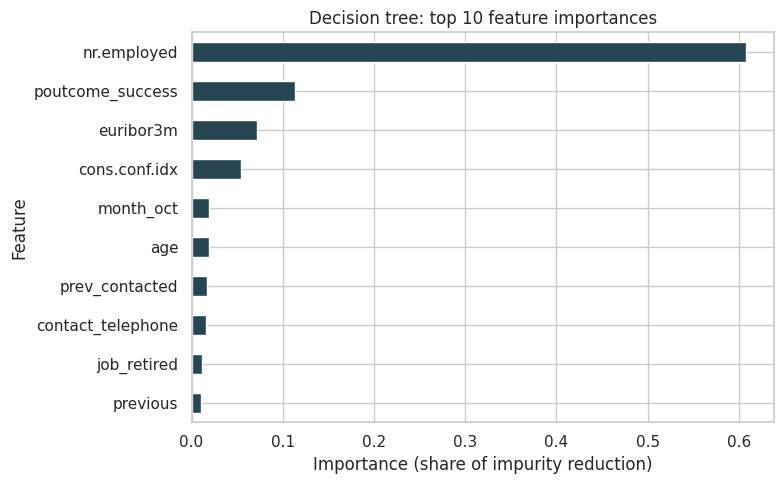

In [33]:
# Decision tree feature importances (share of total impurity reduction per feature)
tree_tuned = tuned_models['Decision Tree']
tree_importance = pd.Series(tree_tuned.named_steps['model'].feature_importances_, index=feature_names)
top_tree = tree_importance.nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
top_tree.plot.barh(ax=ax, color='#264653')
ax.set_title('Decision tree: top 10 feature importances')
ax.set_xlabel('Importance (share of impurity reduction)')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.savefig('images/tree_importances.png', dpi=120)
plt.show()

**Reading the coefficients and importances**

- **Economic context dominates both models.** `nr.employed` alone accounts for ~60% of the Decision Tree's splitting power, and `euribor3m` and `cons.conf.idx` are also in the top four. In the logistic model, `emp.var.rate`, `euribor3m`, `cons.price.idx` and `nr.employed` have the largest coefficients. Because these indicators are highly collinear, their individual logistic coefficients take large, partly offsetting signs (e.g. `emp.var.rate` −1.53 vs `euribor3m` +0.55) and should be read **as a group**: clients subscribe more when interest rates and employment are low. The bank can't control these, but they tell it **when** campaigns will work.
- **Previous success is the strongest client-level signal.** `poutcome_success` is the Tree's 2nd most important feature, and in the logistic model it raises the odds by ~35% (odds ratio 1.35), on top of `prev_contacted`, while a previous *failure* lowers them by ~30% (0.70).
- **Timing:** contacting in **March nearly triples the odds** of subscription (odds ratio 2.82) and December raises them 40%, whereas **May** (the busiest month, a third of all calls) cuts them roughly in half (0.54), with November and June also below average.
- **Channel:** a landline contact lowers the odds (0.74), while cellular raises them (1.31).
- **Client profile:** retirees have ~39% higher odds (1.39). Age itself contributes little once job and other factors are known.
- **Repeated calling:** `campaign` has a negative coefficient (−0.12 per standard deviation, about 2.8 extra calls), so each extra call to the same client in a campaign lowers the odds of success.

*Caveat:* these are associations learned from historical campaigns, not proven causal effects. For example, high-converting months may also have targeted different clients.

## Findings

### Business understanding recap
The bank wants to sell more term deposits with fewer phone calls. We built models that score each client **before the call**, so the call centre can phone the most promising clients first. Because only 11% of calls succeed, we judged models on **how well they rank likely subscribers** (ROC-AUC and lift), not on raw accuracy, which a do-nothing model already scores at 88.7%.

### Model comparison summary

| Model | Test ROC-AUC | Recall (default threshold) | Train time | Verdict |
|---|---|---|---|---|
| **Decision Tree** (depth 7) | **0.806** | 22% | 0.3s | Best ranking, simple rules, fast |
| **Logistic Regression** (C=0.1, balanced) | 0.803 | **65%** | 0.5s | Tied for best ranking, most interpretable, finds the most subscribers |
| KNN (k=101) | 0.795 | 21% | 0.1s (slow to predict) | Close, but no interpretability |
| SVM (RBF) | 0.693 | 24% | 144s | Overfits and ~300x slower: not recommended |

The Decision Tree and Logistic Regression are statistically tied (0.806 vs 0.803 AUC, with near-identical lift curves). **Logistic Regression is recommended for deployment** because its effects are transparent (important for a regulated bank explaining why a client was or wasn't called), it is stable, and its balanced weighting already finds two-thirds of subscribers at the default threshold.

For reference, the original paper reports an AUC of 0.938 for its SVM, but that model used **call duration and other in-call information** that isn't available before dialling. Our ~0.80 AUC is a realistic figure for a model the bank can actually use for targeting.

### Actionable insights

1. **Prioritise the call list by model score.** Calling just the **top 20% of clients reaches about 65% of all subscribers**, and those calls convert at **~37% instead of 11%** (about 3.3x more efficient). The top 10% alone converts at ~52%. The bank could cut call volume by more than half and still keep most of the sales, which is exactly the efficiency goal stated in the paper.
2. **Call past responders first.** Clients who subscribed in a previous campaign convert at **65%**, six times the average. They should be at the top of every campaign list.
3. **Rethink campaign timing.** May carried a third of all calls but had the lowest conversion (6%), while March, September, October and December convert at 44–50%. Spread effort away from May, and plan larger pushes when interest rates are low and the economy is soft, since those periods coincided with far higher uptake.
4. **Prefer mobile numbers.** Cellular contacts convert at about 15% versus 5% for landlines.
5. **Stop calling the same client over and over.** Conversion falls steadily from 13% on the first call to about 5% by the sixth. A cap of around 3 calls per client per campaign would save agent time with little lost revenue.
6. **Focus segments:** students (31%) and retirees (25%) are the most responsive groups. Blue-collar and services clients are the least (7–8%).

## Next Steps and Recommendations

- **Choose the cut-off with the business.** Pick the share of clients to call from the cumulative-gains table using the real cost per call and profit per deposit, rather than using a fixed 0.5 threshold.
- **Pilot it as an A/B test.** Run the next campaign with half the agents using the model-ranked list and half using the current approach, and measure deposits per call. This also tests whether the patterns are causal.
- **Try stronger models.** Ensembles (Random Forest, Gradient Boosting) typically gain a few AUC points on this kind of data. Also run a wider SVM search on more powerful hardware if SVM is still of interest.
- **Add more client data.** Bring in balance, product holdings and digital-banking activity. The paper's authors also note that richer client data is the path to accuracy without in-call information.
- **Plan for changing economic conditions.** The economic indicators drive much of the prediction. Validate the model on later time periods (a time-based split instead of a random one), and retrain regularly as interest rates change.
- **Monitor fairness and client experience.** Check that targeting by age or job doesn't create unfair outcomes, and respect do-not-call preferences.